# Checkpoints Inference TDV
```Authors: Paul Alvarez updated: 20261020```


El presente notebook explora el resultado de entrenar TDV bajo 3 modalidades diferentes, bajo la misma cantidad de iteraciones ytipo de entrenamiento con imágenes naturales (mediante el dataset BSDS500):

- I) Fidelidad Gaussiana con ruido Gaussiano.
- II) Fidelidad Gaussiana con ruido Poisson.
- III) Fidelidad Poisson con ruido Poisson. 

Se ejecutan/replican pruebas de los anteriores notebooks, exploración del resultado de los parámetros aprendidos y un análisis de valores propios replicando la metodología de Kobler et. al.

## Setup

In [8]:
import os
import sys
from pathlib import Path
ROOT = Path(os.path.abspath(os.path.join('..')))
if str(ROOT) not in sys.path: sys.path.append(str(ROOT))

In [14]:
import copy
import json
import numpy as np
import torch
import imageio
from tdv.model import VNet
from notebooks.utils import plot_results, add_poisson_noise

In [10]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_PATHS = {
    'G-5k': ROOT / 'checkpoints/test_5k_gaussian/last.pth',
    'P-L2': ROOT / 'checkpoints/test_5k_poisson/last.pth',
    'P-P': ROOT / 'checkpoints/test_5k_poisson_fidelity/last.pth',
}

TRAIN_CONFIGS = {name: json.loads(path.with_name('config.json').read_text()) for name, path in MODEL_PATHS.items()}

## Checkpoints

In [11]:
def load(name_checkpoint):
    """Carga last.pth (iteracion 5000) con su config y pesos originales."""
    if name_checkpoint not in MODELS:
        checkpoint = torch.load(MODEL_PATHS[name_checkpoint], map_location='cpu', weights_only=False)
        config = copy.deepcopy(checkpoint['config'])
        vn = VNet(config, efficient=False)
        vn.load_state_dict(checkpoint['model'], strict=True)

        MODELS[name_checkpoint] = vn.to(DEVICE).eval()
        CHECKPOINT_INFO[name_checkpoint] = {
            'iteration': checkpoint['iteration'],
            'channels': config['R']['config']['in_channels'],
            'D': config['D']['type'],
        }
    return MODELS[name_checkpoint]


def denoise(name_checkpoints, z):
    vn = load(name_checkpoints)
    
    z_th = torch.from_numpy(np.ascontiguousarray(z.transpose(2, 0, 1)[None])).to(DEVICE)
    with torch.no_grad():
        x = vn(z_th, z_th)[-1][0]
    return x.cpu().numpy().transpose(1, 2, 0)

In [12]:
MODELS = {}
CHECKPOINT_INFO = {}

print(f"{'Modelo':<8} {'Iter':>6} {'S':>3} {'T':>12} {'lambda':>12} {'D':>10} {'prox':>6}")
for name in MODEL_PATHS:
    vn = load(name)
    print(f"{name:<8} {CHECKPOINT_INFO[name]['iteration']:>6} {vn.S:>3} "
          f"{vn.T.item():>12.7f} {vn.lmbda.item():>12.7f} "
          f"{CHECKPOINT_INFO[name]['D']:>10} {str(vn.use_prox):>6}")

Modelo     Iter   S            T       lambda          D   prox
G-5k       5000  10    0.0980325    0.0299958    denoise   True
P-L2       5000  10    0.1042969    0.0399166    denoise   True
P-P        5000  10    0.1048099    0.0934656    poisson   True


## Validation

### Resultados


Una porción de dataset BSDS500 se usa para validar los resultados del algoritmo, BSDS68. A continuación, se presentan las salidas de dicha evaluación sobre cada checkpoint:


| Modelo | Fidelidad | Ruido de entrenamiento | Ruido de validación | PSNR entrada (dB) | PSNR salida (dB) |
|:--|:--|:--|:--|--:|--:|
| G-5k* | Gaussiana (L2)* | Gaussiano | Gaussiano, $\sigma=25$ | 20.17 | 31.20 |
| G-5k | Gaussiana (L2) | Gaussiano | Poisson, peak = 50 | 20.91 | 30.31 |
| P-L2 | Gaussiana (L2) | Poisson | Poisson, peak = 50 | 20.91 | 31.61 |
| P-P | Poisson | Poisson | Poisson, peak = 50 | 21.28 | 31.08 |

**Nota:** La comparación G-5K con fidelidad gaussiana se usa como referencia comparativa a los pesos reales presentados por los autores, tomando de referencia el valor PSNR = 31.35 db que obtuvieron, se presenta prácticamente igual considerando el reducido número de iteraciones empleado.

### Registro de entrenamiento de P-P

Cabe resaltar, en el entrenamineto con ruido poisson, independiente de la fidelidad utilizada, se presentaron a lo largo de las iteraciones, lotes rechazados:

| Dato reportado | Valor |
|:--|--:|
| Mejor PSNR | 31.080 dB |
| Tiempo | 1.32 h |
| VRAM pico | 9.98 GB |
| Lotes rechazados | 116 de 5000 |
| Máximo de rechazos consecutivos | 25 |
| Rebobinados | 3 |


### Comandos




**G-5k con ruido gaussiano**

```bash
python evaluate.py runs/test_5k_gaussian/best.pth --file-list datasets/bsds500/cbsd68.txt
```

La salida indica $\sigma=25$ y $S=10$.

**G-5k con ruido Poisson**

```bash
python evaluate.py runs/test_5k_gaussian/best.pth \
    --file-list datasets/bsds500/cbsd68.txt \
    --noise-type poisson \
    --poisson-peak 50
```

**P-L2 con ruido Poisson**

```bash
python evaluate.py runs/test_5k_poisson/best.pth \
    --file-list datasets/bsds500/cbsd68.txt \
    --noise-type poisson \
    --poisson-peak 50
```

**P-P con ruido Poisson**

```bash
python evaluate.py runs/test_5k_poisson_fidelity/best.pth \
    --file-list datasets/bsds500/cbsd68.txt \
    --noise-type poisson \
    --poisson-peak 50
```


## Water-castle



In [17]:
peak_castle = float(TRAIN_CONFIGS['P-L2']['poisson_peak'])
y_castle = imageio.v2.imread(ROOT / 'data/water-castle.png').astype(np.float32) / 255
z_castle, _ = add_poisson_noise(y_castle, peak= peak_castle)

### G-5k

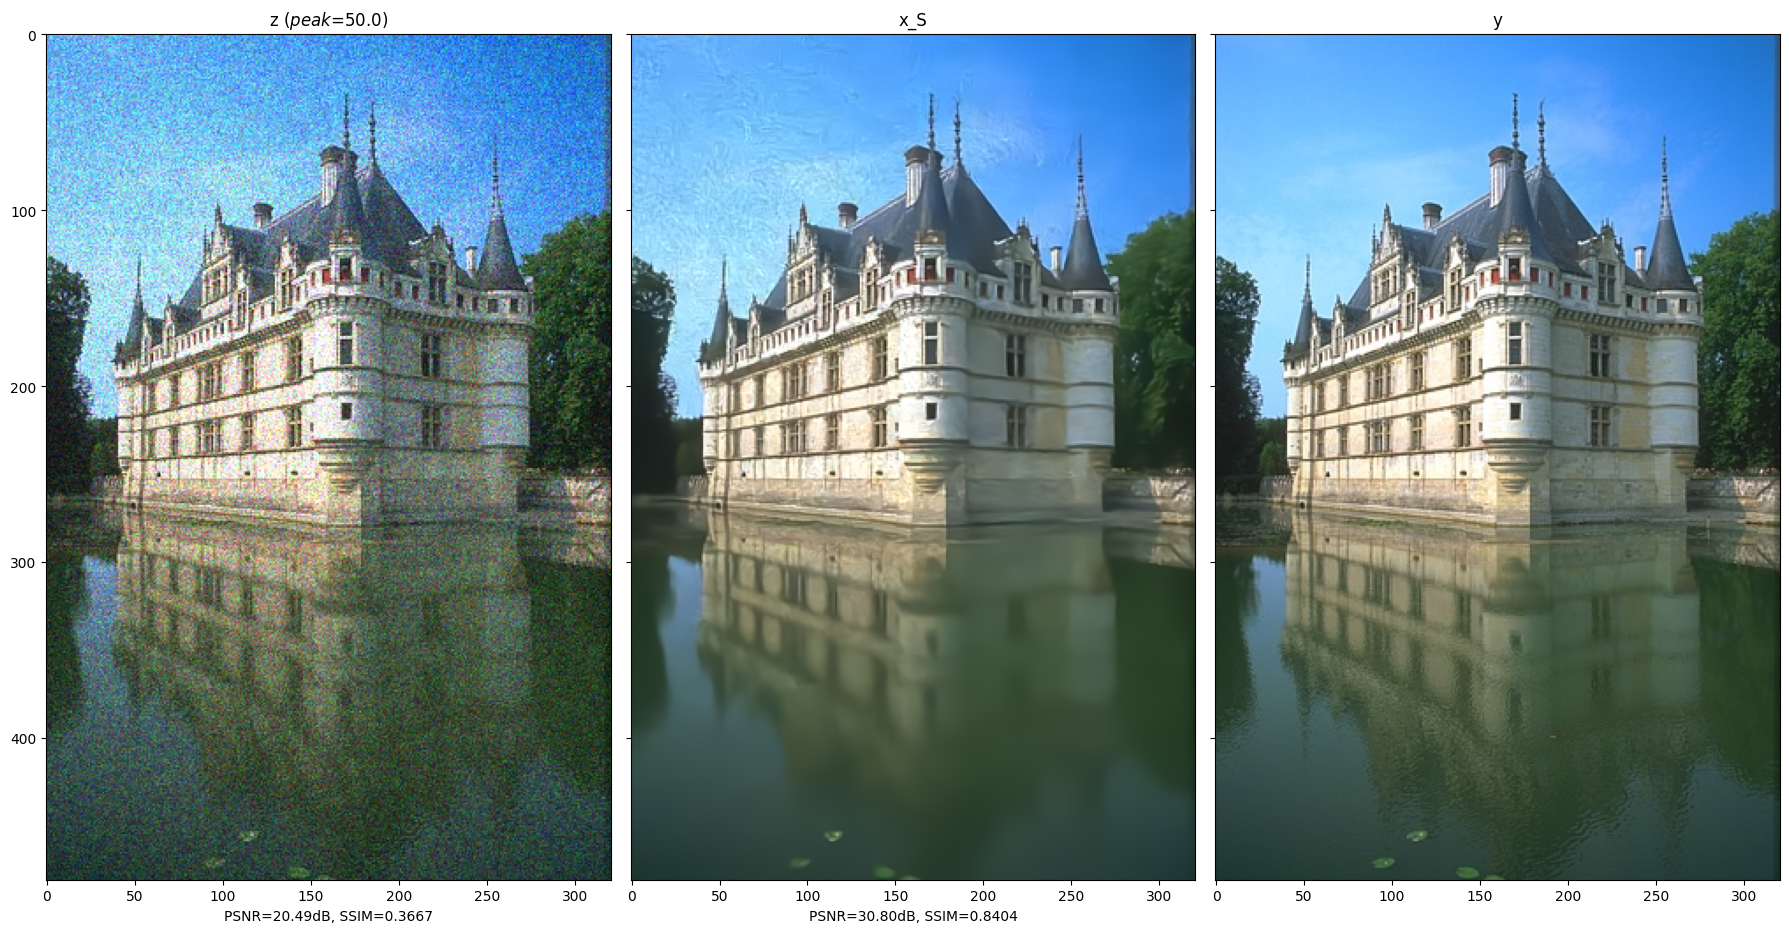

In [21]:
x_castle_g5k = denoise('G-5k', z_castle)
plot_results(z_castle, x_castle_g5k, y_castle, peak=peak_castle, origin='upper')

### P-L2

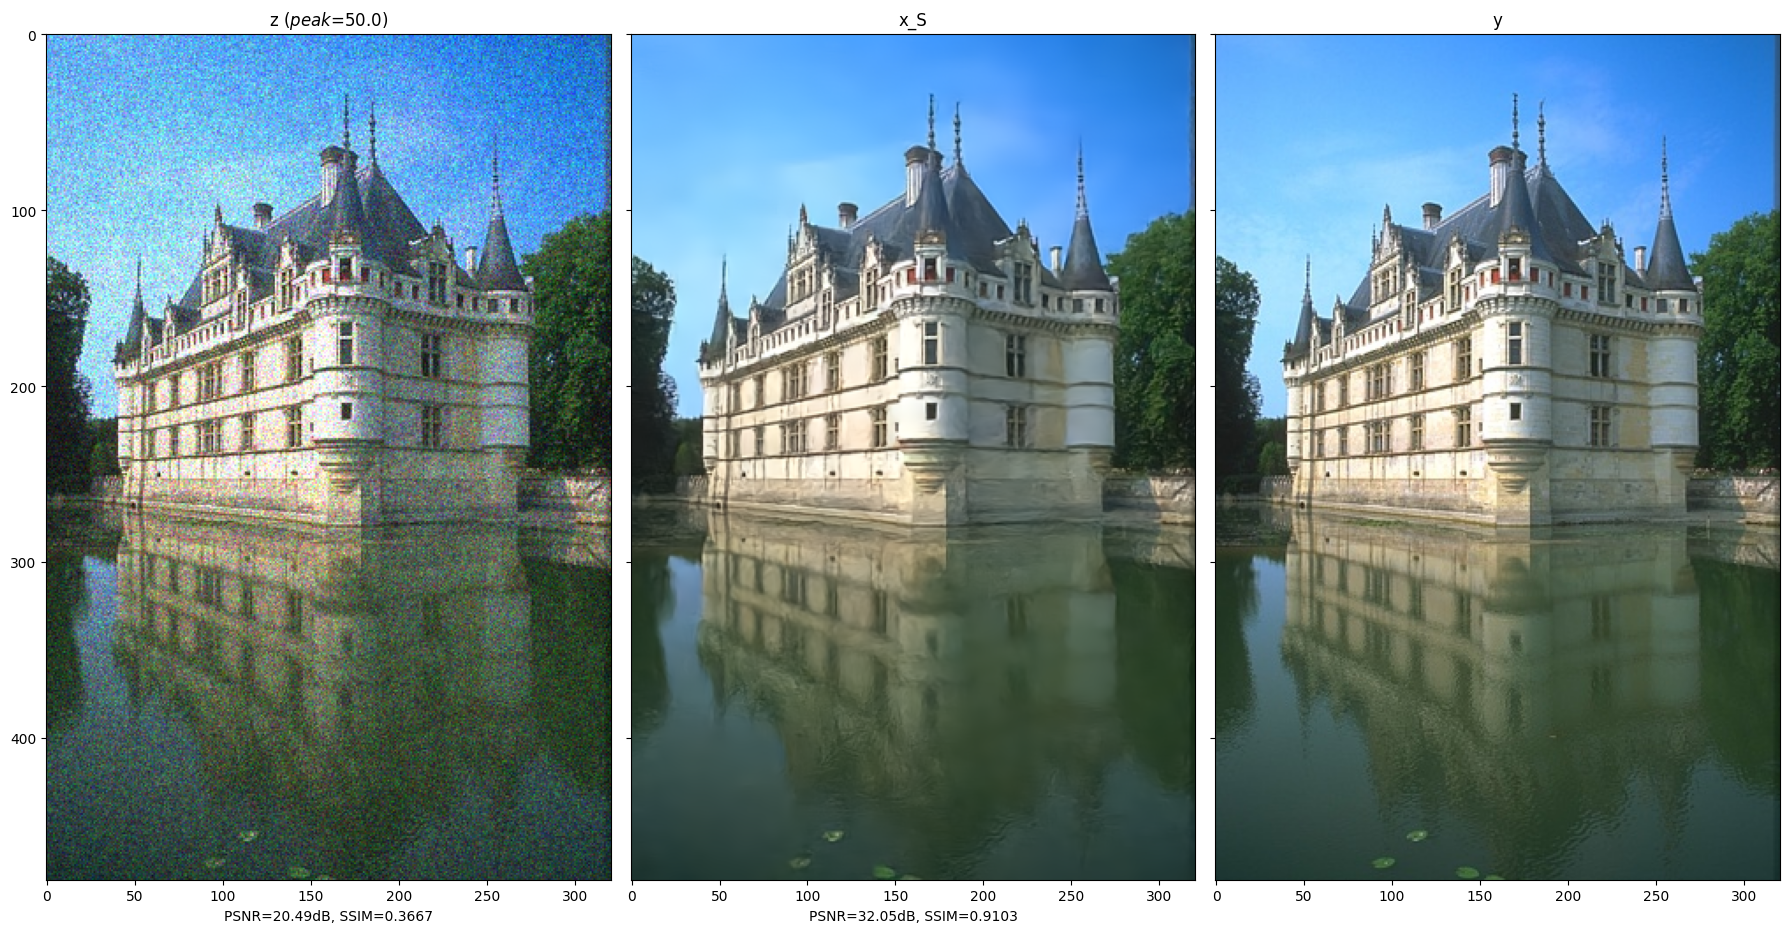

In [22]:
x_castle_pl2 = denoise('P-L2', z_castle)
plot_results(z_castle, x_castle_pl2, y_castle, peak=peak_castle, origin='upper')


### P-P

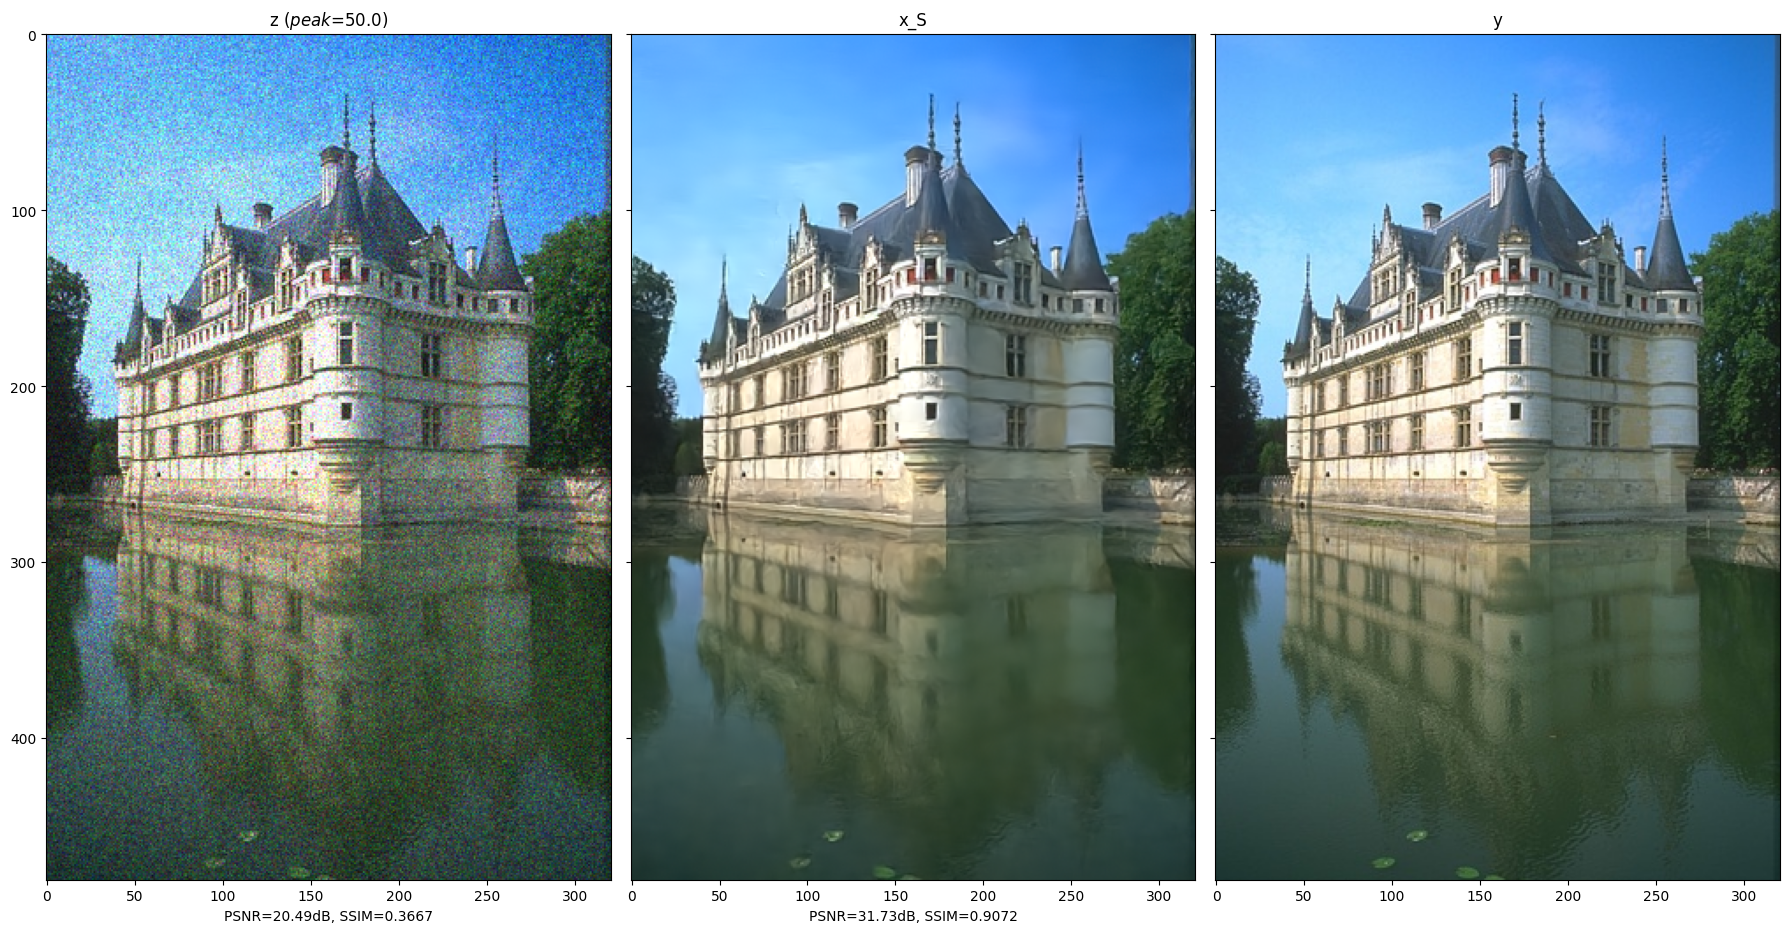

In [23]:
x_castle_pp = denoise('P-P', z_castle)
plot_results(z_castle, x_castle_pp, y_castle, peak=peak_castle, origin='upper')
